ThickCurr Example: Eddy currents in a conducting slab {#doc_thickcurr_slab_ex}
==========
In this example we use the \ref OpenFUSIONToolkit.ThickCurr.ThickCurr "ThickCurr" python interface to model eddy currents in volumetric ("thick") conducting structures. A stainless steel slab ($\eta = 7 \times 10^{-7} \Omega \cdot m$, thickness 0.2 m) is placed at the center of a 1 m cube with perfectly conducting walls, with the remainder of the cube treated as vacuum. We will:

 1. Compute the slowest decay times (L/R time constants) of the system with an eigenvalue solve
 2. Release an initial magnetic field and follow its decay in time, recording signals from a flux loop and a magnetic probe
 3. Generate plot files of the eigenmodes and time-dependent fields for ParaView

ThickCurr evolves the vector potential ($B = \nabla \times A$, $E = -\partial A / \partial t$) following
$$ \frac{1}{\eta} \frac{\partial A}{\partial t} + \nabla \times \left( \frac{1}{\mu_0} \nabla \times A \right) = 0 $$
where vacuum regions are treated as a pseudo-vacuum with a large resistivity.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,4)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

### Load ThickCurr library

To load the ThickCurr python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

For the sensors used below we also import sensor classes from \ref OpenFUSIONToolkit.ThinCurr.sensor "ThinCurr", which can be used with ThickCurr without modification.

In [2]:
oft_python_path = os.getenv('OFT_ROOTPATH')
if oft_python_path is not None:
    sys.path.append(os.path.join(oft_python_path,'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.ThickCurr import ThickCurr
from OpenFUSIONToolkit.ThinCurr.sensor import Mirnov, circular_flux_loop, flux_loop

## Analytic solution
For this geometry the slowest mode varies as $cos(\pi x)$ (or $cos(\pi y)$), giving a horizontal wavenumber $\kappa = \pi$. Matching a potential field in each vacuum layer (with $B_z = 0$ on the top and bottom walls) to the slab eigenmode $h(z) = cos(s(z-z_c))$, where $z_c = 0.5$ is the center of the slab, gives
$$ s \; tan(s d / 2) = \kappa \; coth(\kappa z_1) $$
where $d = 0.2$ m is the slab thickness and $z_1 = 0.4$ m is the height of the lower vacuum layer. The decay time is then $\tau = \mu_0 / (\eta (s^2 + \kappa^2))$. As the mode can vary in either the $x$ or $y$ direction, the slowest decay time is 2-fold degenerate.

In [3]:
from scipy.optimize import brentq
mu0 = 4.E-7*np.pi
eta = 7.E-7        # Resistivity of slab [Ohm-m]
z1, d = 0.4, 0.2   # Height of lower vacuum layer and slab thickness [m]
kappa = np.pi
s = brentq(lambda s: s*np.tan(s*d/2.0) - kappa/np.tanh(kappa*z1), 1.E-6, np.pi/d*(1.0-1.E-10))
tau_analytic = mu0/(eta*(s**2 + kappa**2))
print('Analytic decay time = {0:.2f} ms'.format(tau_analytic*1.E3))

Analytic decay time = 42.05 ms


## Setup model

### Initialize ThickCurr object
First we create the OFT environment and a ThickCurr instance.

In [4]:
myOFT = OFT_env(nthreads=2)
tc_model = ThickCurr(myOFT)

#----------------------------------------------
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Base release:        
Development branch:  claude/optimistic-franklin-n8hrmq
Revision id:         ddd8994

Parallelization Info:
  # of MPI tasks      =    1
  # of NUMA nodes     =    1
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------



### Load mesh and build model
Next we load the mesh and build the model using \ref OpenFUSIONToolkit.ThickCurr.ThickCurr.setup_model "setup_model()". The mesh file (`thickcurr_slab.h5`) included with this example was generated using the script `create_slab_mesh.py`, which can be modified to change the resolution or geometry. The slab is region 2 in the mesh and the vacuum is region 1.

The resistivity of each conducting region is specified in the XML input file (`oft_in.xml`) using `region` elements, where `id` gives the mesh region IDs and `eta` the resistivity in $\Omega \cdot m$. All other regions are treated as a pseudo-vacuum. A preconditioner for the linear solver is also specified, which in this case uses a direct solve (LU factorization). Alternatively, resistivities can be passed directly using the `eta_values` argument (eg. `eta_values=[-1.0, 7.E-7]`, where values $\le 0$ indicate vacuum).

The time step `dt` is used for the time-dependent simulation and, by default, as the shift for the eigenvalue solve. Here we use backward Euler time stepping (`theta=1`).

```xml
<oft>
  <thickcurr>
    <region>
      <id>2</id>
      <eta>7.0E-7</eta>
    </region>
    <pre type="block_jacobi">
      <nlocal>1</nlocal>
      <solver type="lu"></solver>
    </pre>
  </thickcurr>
</oft>
```

\note The pseudo-vacuum makes the linear system ill-conditioned for iterative methods, so a direct solve is used. In parallel, the block-Jacobi preconditioner shown here only factors the local portion of the matrix on each process and convergence degrades significantly with the number of processes, so this example should be run in serial (see \ref doc_thickcurr_torus_ex for a preconditioner that scales better to larger problems).

In [5]:
tc_model.setup_model(mesh_file='thickcurr_slab.h5', order=2, xml_filename='oft_in.xml', dt=2.E-3, theta=1.0, lin_tol=1.E-10)


**** Loading OFT mesh
  Native volume mesh:
    Filename = thickcurr_slab.h5

**** Generating grid level  1
  Generating domain linkage
  Generating boundary domain linkage
  Mesh statistics:
    Volume          =  1.000E+00
    Surface area    =  6.000E+00
    # of points     =     784
    # of edges      =    4455
    # of faces      =    6912
    # of cells      =    3240
    # of boundary points =     434
    # of boundary edges  =    1296
    # of boundary faces  =     864
    # of boundary cells  =     810
  Resolution statistics:
    hmin =  6.667E-02
    hrms =  1.826E-01
    hmax =  2.449E-01
  Surface grounded at vertex       7


**** Creating Lagrange FE space
  Order  =    2
  Minlev =    2


**** Creating H^1 FE space
  Order  =    3
  Minlev =    2


**** Creating H(Curl) FE space
  Order  =    2
  Minlev =    2


**** Creating H(Curl) + Grad(H^1) FE space
  Order  =    2
  Minlev =    2




ThickCurr setup
  dt         =   2.000E-03
  theta      =   1.000E+00
  eta_vac    =   7.000E-03
  L-Tol      =   1.000E-10
  MG levels  =    2 ->    2
  Regions:
       1: vacuum
       2: eta [Ohm-m] =   7.000E-07
  # A-DOFs   =   3.488E+04
    Active   =   1.804E+04
    Vac-grad =   9.576E+03
  Setup time =   8.814E-01



## Compute decay times
The slowest decaying modes of the system are computed using \ref OpenFUSIONToolkit.ThickCurr.ThickCurr.get_eigs "get_eigs()", which returns the time constants in order of decreasing decay time. With `save_plot=True` each mode is saved to the plot group `thickcurr_eigs` in the `eigs/` subdirectory, using the mode index as the "time".

In [6]:
tau_eigs = tc_model.get_eigs(4, save_plot=True)
for i, tau in enumerate(tau_eigs):
    print('Mode {0}: tau = {1:.3f} ms'.format(i+1, tau*1.E3))

Starting ThickCurr eigenvalue solve
  nev        =      4
  Shift      =   2.000E-03
 Starting IRL solver


 Fetching EVs
 Solve Complete:
     0.90719040385701344       0.93706318992899751       0.95459370394260645       0.95459524617797553     
 Solve Complete  0.90719040385701344       0.93706318992899751       0.95459370394260645       0.95459524617797553     
  Decay times [s]:
       1   4.2048251E-02
       2   4.2046755E-02
       3   2.9777905E-02
       4   1.9549496E-02



Mode 1: tau = 42.048 ms
Mode 2: tau = 42.047 ms
Mode 3: tau = 29.778 ms
Mode 4: tau = 19.549 ms


## Time-dependent simulation

### Initial condition
For the time-dependent run we set an initial vector potential using \ref OpenFUSIONToolkit.ThickCurr.ThickCurr.set_field "set_field()", which takes a function that returns the vector potential at a set of points. Here we use
$$ A_0 = B_0 L / \pi \; sin(\pi x / L) sin(\pi z / L) \hat{y} $$
whose tangential component vanishes on the boundary of the cube. This corresponds to a magnetic field
$$ B_0 = B_0 \left[ -sin(\pi x / L) cos(\pi z / L) \hat{x} + cos(\pi x / L) sin(\pi z / L) \hat{z} \right] $$
that threads the slab vertically, with the same $x$ variation as the slowest decaying mode.

The field is projected onto the finite element basis with the tangential components of $A$ on the boundary, which are held fixed in time by the perfectly conducting walls, set to zero (`zero_boundary=True`). Otherwise small projection errors on the boundary would support a (small) static field. The magnetic energy of the projected field is returned.

In [7]:
B0 = 1.E-2   # Peak initial magnetic field [T]
L = 1.0      # Size of cube [m]
def A_init(pts):
    A = np.zeros(pts.shape)
    A[:,1] = B0*L/np.pi*np.sin(np.pi*pts[:,0]/L)*np.sin(np.pi*pts[:,2]/L)
    return A

energy0 = tc_model.set_field(A_init)
print('Initial magnetic energy = {0:.4E} J'.format(energy0))

Starting CG solver
     0  0.000000E+00  0.000000E+00  2.642571E-04
     1 -7.940487E-07  1.961496E-02  1.973897E-04  1.006322E-02
     2 -1.026864E-06  2.508229E-02  1.070546E-04  4.268136E-03
     3 -1.146856E-06  2.745035E-02  7.948343E-05  2.895534E-03
     4 -1.198663E-06  2.825107E-02  5.807123E-05  2.055541E-03
     5 -1.220318E-06  2.820654E-02  3.030858E-05  1.074523E-03
     6 -1.228209E-06  2.781157E-02  2.351618E-05  8.455539E-04
     7 -1.233433E-06  2.709116E-02  2.519487E-05  9.300033E-04
     8 -1.239336E-06  2.594016E-02  2.000663E-05  7.712609E-04
     9 -1.241440E-06  2.541112E-02  1.522368E-05  5.990953E-04
    10 -1.244245E-06  2.439392E-02  1.566183E-05  6.420382E-04
    20 -1.262603E-06  1.458053E-02  7.928484E-06  5.437719E-04
    30 -1.265619E-06  1.267114E-02  4.225324E-06  3.334603E-04
    40 -1.266391E-06  1.239479E-02  1.750469E-06  1.412262E-04
    50 -1.266483E-06  1.240572E-02  7.533045E-07  6.072234E-05
    60 -1.266507E-06  1.240044E-02  3.358879E-07  

    90 -1.266514E-06  1.239279E-02  5.439998E-08  4.389646E-06
   100 -1.266514E-06  1.239263E-02  1.620391E-08  1.307544E-06
   110 -1.266514E-06  1.239252E-02  7.933204E-09  6.401609E-07
   120 -1.266514E-06  1.239253E-02  4.027099E-09  3.249617E-07
   130 -1.266514E-06  1.239253E-02  1.915851E-09  1.545972E-07
   140 -1.266514E-06  1.239254E-02  9.475704E-10  7.646298E-08
   150 -1.266514E-06  1.239254E-02  4.092328E-10  3.302250E-08
   160 -1.266514E-06  1.239255E-02  1.847788E-10  1.491048E-08
   170 -1.266514E-06  1.239255E-02  6.690190E-11  5.398560E-09
   180 -1.266514E-06  1.239255E-02  3.578305E-11  2.887466E-09


   190 -1.266514E-06  1.239255E-02  1.600805E-11  1.291748E-09
   200 -1.266514E-06  1.239255E-02  8.504043E-12  6.862224E-10
   210 -1.266514E-06  1.239255E-02  3.851141E-12  3.107627E-10
Initial magnetic energy = 1.9897E+01 J


### Define sensors
Sensors are defined using the same classes as ThinCurr and set up with \ref OpenFUSIONToolkit.ThickCurr.ThickCurr.setup_sensors "setup_sensors()". Here we add:
 - A rectangular flux loop in the midplane of the slab ($z = 0.5$, $0.05 < x < 0.45$, $0.05 < y < 0.95$), which measures the vertical flux through the slab. In ThickCurr flux loops are evaluated as $\oint A \cdot dl$, so the mesh does not need to conform to a surface bounded by the loop.
 - A point magnetic probe (\ref OpenFUSIONToolkit.ThinCurr.sensor.Mirnov "Mirnov" with `dx=None`) in the upper vacuum region, measuring $B_z$.

The initial signals can be checked against the analytic values using \ref OpenFUSIONToolkit.ThickCurr.ThickCurr.eval_sensors "eval_sensors()".

In [8]:
floop_pts = np.array([[0.05,0.05,0.5], [0.45,0.05,0.5], [0.45,0.95,0.5], [0.05,0.95,0.5], [0.05,0.05,0.5]])
sensors = [
    flux_loop(floop_pts, 'SLAB_FLUX'),
    Mirnov([0.25,0.5,0.75], [0.0,0.0,1.0], 'BZ_UPPER', dx=None)
]
sensor_obj = tc_model.setup_sensors(sensors)
signals0 = tc_model.eval_sensors(sensor_obj)
signals0_analytic = [
    B0*L*(np.sin(0.45*np.pi)-np.sin(0.05*np.pi))/np.pi*0.9,
    B0*np.cos(np.pi*0.25)*np.sin(np.pi*0.75)
]
for name, val, val_exp in zip(sensor_obj['names'], signals0, signals0_analytic):
    print('{0:10}: {1:.4E} (analytic = {2:.4E})'.format(name, val, val_exp))

SLAB_FLUX : 2.3789E-03 (analytic = 2.3814E-03)
BZ_UPPER  : 4.9674E-03 (analytic = 5.0000E-03)


### Run simulation
The time-dependent simulation is run using \ref OpenFUSIONToolkit.ThickCurr.ThickCurr.run_td "run_td()", which advances the vector potential and saves restart files containing the solution every `plot_freq` steps. The magnetic energy and Ohmic power dissipated in conductors are recorded to the history file `thickcurr.hist` and the sensor signals to `floops.hist`.

In [9]:
tc_model.run_td(nsteps=150, plot_freq=5, sensor_obj=sensor_obj)

Starting ThickCurr time advance
  t0         =   0.000E+00
  dt         =   2.000E-03
  nsteps     =      150
  Mag Energy =   1.990E+01

  Step  Lits         Time       Energy        Power     Walltime


     1     1  2.00000E-03  1.52663E+01  8.71530E+02  2.04097E-01
     2     1  4.00000E-03  1.38368E+01  6.82327E+02  1.80757E-01


     3     1  6.00000E-03  1.25942E+01  6.03845E+02  1.77184E-01


     4     1  8.00000E-03  1.14736E+01  5.46681E+02  2.08849E-01


     5     1  1.00000E-02  1.04547E+01  4.97435E+02  2.09425E-01


     6     1  1.20000E-02  9.52671E+00  4.53139E+02  2.03467E-01
     7     1  1.40000E-02  8.68120E+00  4.12893E+02  2.00335E-01


... (90 outputs left out)

   145     1  2.90000E-01  2.33669E-05  1.11135E-03  1.83210E-01
   146     1  2.92000E-01  2.12931E-05  1.01272E-03  1.89003E-01


   147     1  2.94000E-01  1.94033E-05  9.22839E-04  1.89708E-01
   148     1  2.96000E-01  1.76813E-05  8.40937E-04  1.85655E-01


   149     1  2.98000E-01  1.61121E-05  7.66305E-04  1.87129E-01
   150     1  3.00000E-01  1.46821E-05  6.98296E-04  1.99727E-01


0.3000000000000002

### Plot energy and sensor histories
After a short initial transient, as the field in the vacuum regions relaxes and faster modes decay, the energy and sensor signals decay with the slowest decay time.

\note With backward Euler time stepping (`theta=1`), a mode with decay time $\tau$ is advanced with an effective decay time of $\Delta t / ln(1 + \Delta t / \tau)$, which is approximately 2% longer than the exact value for the time step used here. Crank-Nicolson (`theta=0.5`) is more accurate for the conducting regions, but only weakly damps the stiff pseudo-vacuum modes, which can then oscillate from step to step.

findfont: Failed to find font weight bold for STIXSizeFiveSym, now using 400.


findfont: Failed to find font weight bold for cmmi10, now using 400.


findfont: Failed to find font weight bold for cmsy10, now using 400.


findfont: Failed to find font weight bold for cmr10, now using 400.


findfont: Failed to find font weight bold for cmtt10, now using 400.


findfont: Failed to find font weight bold for cmti10, now using 400.


findfont: Failed to find font weight bold for cmb10, now using 400.


findfont: Failed to find font weight bold for cmss10, now using 400.


findfont: Failed to find font weight bold for cmex10, now using 400.


findfont: Failed to find font weight bold for DejaVu Sans Display, now using 400.


Effective decay time with backward Euler = 43.04 ms


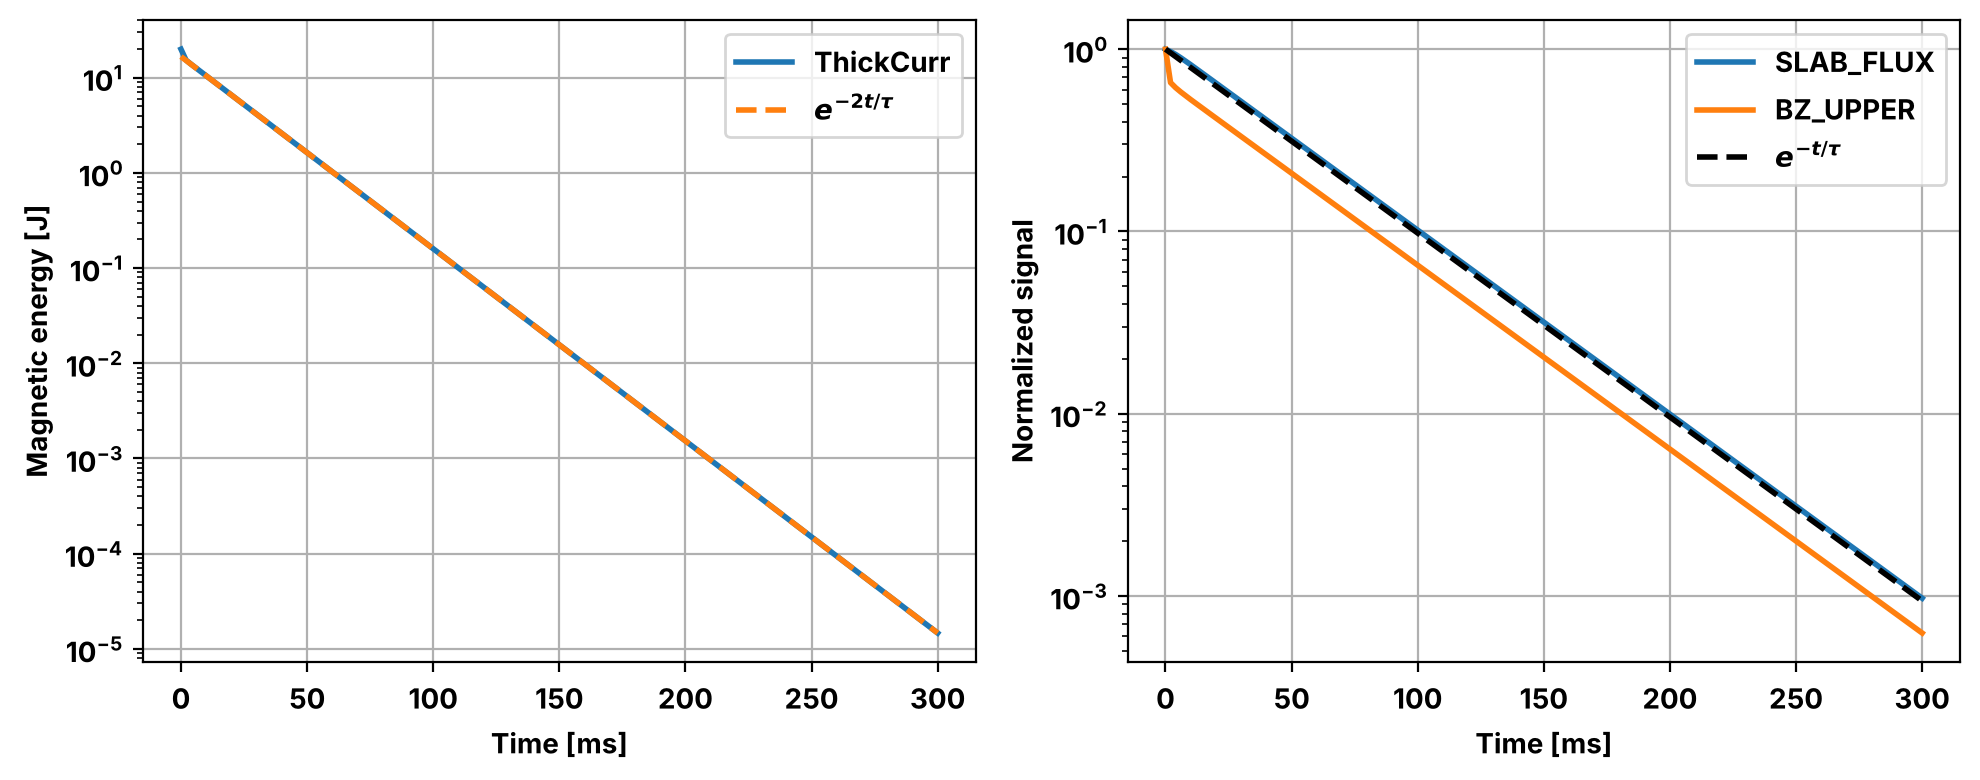

In [10]:
hist = tc_model.load_history('thickcurr.hist')
sensor_hist = tc_model.load_history('floops.hist')
dt = 2.E-3
tau_eff = dt/np.log(1.0+dt/tau_eigs[0])
print('Effective decay time with backward Euler = {0:.2f} ms'.format(tau_eff*1.E3))

fig, ax = plt.subplots(1,2,figsize=(10,4),tight_layout=True)
time = hist['time']
ax[0].semilogy(time*1.E3, hist['energy'], label='ThickCurr')
ax[0].semilogy(time*1.E3, hist['energy'][-1]*np.exp(-2.0*(time-time[-1])/tau_eff), '--', label=r'$e^{-2t/\tau}$')
ax[0].set_ylabel('Magnetic energy [J]')
time = sensor_hist['time']
for name in sensor_obj['names']:
    signal = sensor_hist[name]
    ax[1].semilogy(time*1.E3, abs(signal/signal[0]), label=name)
ax[1].semilogy(time*1.E3, np.exp(-time/tau_eff), 'k--', label=r'$e^{-t/\tau}$')
ax[1].set_ylabel('Normalized signal')
for ax_tmp in ax:
    ax_tmp.grid(True)
    ax_tmp.legend()
    ax_tmp.set_xlabel('Time [ms]')

## Visualization in ParaView
To visualize the time-dependent solution, \ref OpenFUSIONToolkit.ThickCurr.ThickCurr.plot_td "plot_td()" steps through the restart files and saves the vector potential (`A`), magnetic field (`B`), electric field (`E`), and current density (`J`, which is zero in vacuum regions) to plot files. \ref OpenFUSIONToolkit.ThickCurr.ThickCurr.build_XDMF "build_XDMF()" then generates the `*.xmf` files that can be loaded by [ParaView](https://www.paraview.org/), [VisIt](https://visit-dav.github.io/visit-website/index.html), or other visualization programs, for both the time-dependent fields (run directory) and the eigenmodes (`eigs` subdirectory).

The resulting `thickcurr_vmesh-*.xmf` (or `eigs/thickcurr_eigs_vmesh-*.xmf`) files can be opened in ParaView as a time series. The current density (`J`) is a good choice for visualizing the eddy currents in the slab, for example using a "Slice" or "Glyph" filter. `J` is computed from the electric field in each conducting region ($J = E / \eta$) and is zero in vacuum regions. Surface currents on the perfectly conducting walls are not included.

In [11]:
tc_model.plot_td(plot_freq=5)
td_plot, eig_plot = tc_model.build_XDMF()


  Starting ThickCurr post-processing
    thickcurr_00000.rst: t =   0.00000E+00


    thickcurr_00005.rst: t =   1.00000E-02


    thickcurr_00010.rst: t =   2.00000E-02


    thickcurr_00015.rst: t =   3.00000E-02


    thickcurr_00020.rst: t =   4.00000E-02
    thickcurr_00025.rst: t =   5.00000E-02


    thickcurr_00030.rst: t =   6.00000E-02
    thickcurr_00035.rst: t =   7.00000E-02


... (18 outputs left out)

    thickcurr_00140.rst: t =   2.80000E-01


    thickcurr_00145.rst: t =   2.90000E-01


    thickcurr_00150.rst: t =   3.00000E-01



Creating output files: oft_xdmf.XXXX.h5
  Removing old Xdmf files
    Removed 0 files
  Found Group: thickcurr
    Found Mesh: smesh
      # of blocks: 1
    Found Mesh: vmesh
      # of blocks: 1

Creating output files: oft_xdmf.XXXX.h5
  Removing old Xdmf files
    Removed 0 files
  Found Group: thickcurr_eigs
    Found Mesh: smesh
      # of blocks: 1
    Found Mesh: vmesh
      # of blocks: 1
